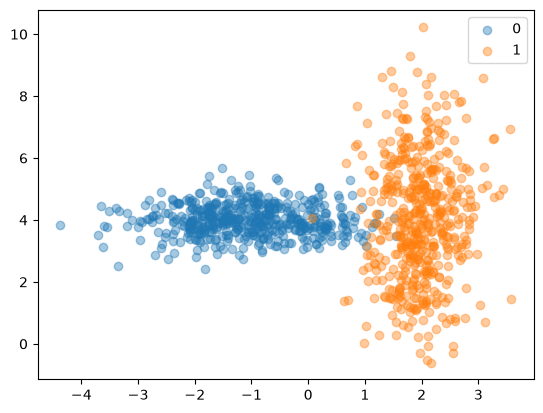

In [1]:
import numpy as np
import matplotlib.pyplot as plt

%matplotlib inline

#kita gunakan 2D dataset buatan
n_samples = 1000
X0 = np.random.normal(loc=[-1,4], scale=[1,0.5], size=(int(n_samples/2), 2))
X1 = np.random.normal(loc=[2,4], scale=[0.5,2], size=(int(n_samples/2), 2))
y0 = np.zeros(shape=(int(n_samples/2), ))
y1 = np.ones(shape=(int(n_samples/2), ))
X = np.vstack([X0, X1])
yhat = np.hstack([y0, y1])

#kita tampilkan terlebih dahulu
plt.scatter(*X[yhat==0].T, label='0', alpha=0.4); plt.scatter(*X[yhat==1].T, label='1', alpha=0.4)
plt.legend();

In [5]:
def f(z):
    return 1 / (1 + np.exp(-z))

def dfdz(z):
    return f(z) * (1 - f(z))

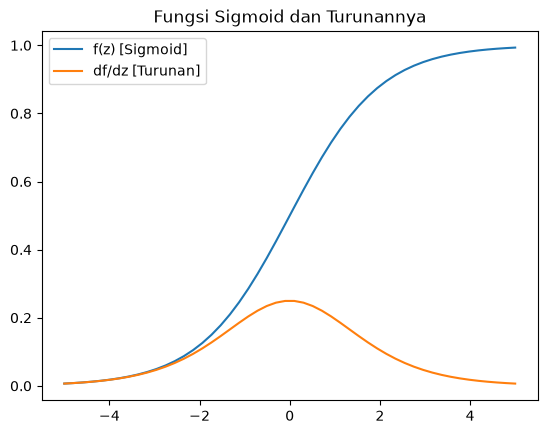

In [10]:

# ==========================================
# 2. DEFINISI FUNGSI AKTIVASI & LOSS
# ==========================================
def f(z):
    return 1 / (1 + np.exp(-z))

def dfdz(z):
    return f(z) * (1 - f(z))

def J(y, yhat):
    eps = 1e-8
    return -(yhat * np.log(y+eps) + (1-yhat) * np.log(1-y+eps))

def dJdy(y, yhat):
    eps = 1e-8
    return (1-yhat)/(1-y+eps) - yhat/(y+eps)

# Menampilkan grafik fungsi Sigmoid
z = np.linspace(-5,5)
plt.figure("Fungsi Aktivasi")
plt.plot(z, f(z), label='f(z) [Sigmoid]')
plt.plot(z, dfdz(z), label='df/dz [Turunan]')
plt.legend()
plt.title('Fungsi Sigmoid dan Turunannya')

# Tampilkan semua grafik di IDLE
plt.show()

Memulai pelatihan jaringan saraf...
Epoch 0 -> Akurasi Pelatihan: 53.30%
Epoch 50 -> Akurasi Pelatihan: 96.70%
Epoch 100 -> Akurasi Pelatihan: 97.30%
Epoch 150 -> Akurasi Pelatihan: 97.80%
Epoch 200 -> Akurasi Pelatihan: 97.80%
Epoch 249 -> Akurasi Pelatihan: 97.90%


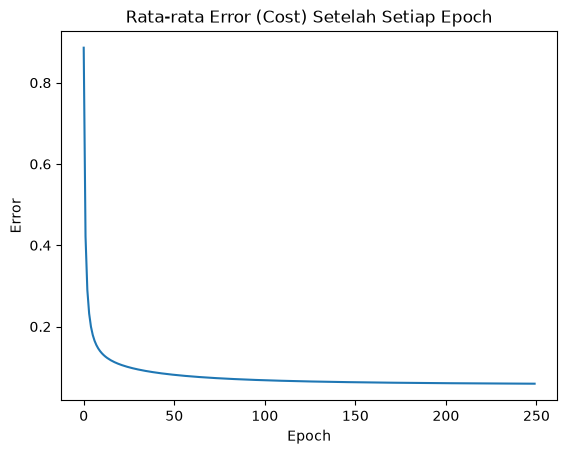

In [9]:
import numpy as np
import matplotlib.pyplot as plt

# --- PENTING: KODE DI BAWAH INI ADALAH PROGRAM UTUH DARI AWAL SAMPAI PELATHIAN ---

n_samples = 1000
X0 = np.random.normal(loc=[-1,4], scale=[1,0.5], size=(int(n_samples/2), 2))
X1 = np.random.normal(loc=[2,4], scale=[0.5,2], size=(int(n_samples/2), 2))
y0 = np.zeros(shape=(int(n_samples/2), ))
y1 = np.ones(shape=(int(n_samples/2), ))
X = np.vstack([X0, X1])
yhat = np.hstack([y0, y1])

def f(z): return 1 / (1 + np.exp(-z))
def J(y, yhat):
    eps = 1e-8
    return -(yhat * np.log(y+eps) + (1-yhat) * np.log(1-y+eps))

# Fungsi prediksi (Forward Pass)
def forward(x, w):
    return f(np.dot(x, w))

# Fungsi hitung langkah mundur (Backward Pass)
def backward2(x, y, yhat):
    return ( y*(1-yhat) - yhat*(1-y) ) * x

def update(w, alpha, step):
    return w - alpha * step

# Fungsi Utama Pelatihan
def train(X, yhat, n_epoch, alpha):
    X_withbias = np.hstack([np.ones((X.shape[0],1)), X])
    costs = np.zeros(shape=(n_epoch,))
    w = np.random.normal(0, 0.01, size=(X.shape[1]+1,))
    
    for epoch in range(n_epoch):
        for i, x in enumerate(X_withbias):
            y = forward(x, w)
            step = backward2(x, y, yhat[i])
            w = update(w, alpha, step)
        
        predictions = forward(X_withbias, w)
        costs[epoch] = np.mean(J(predictions, yhat))
        
        if ((epoch % 50) == 0) or (epoch == (n_epoch - 1)):
            accuracy = np.mean(predictions.round() == yhat)
            print(f'Epoch {epoch} -> Akurasi Pelatihan: {accuracy:.2%}')
            
    return w, costs

# Menjalankan Pelatihan
n_epoch = 250
alpha = 0.01
print("Memulai pelatihan jaringan saraf...")
w, costs = train(X, yhat, n_epoch, alpha)

# Tampilkan grafik penurunan error (Cost)
plt.figure("Hasil Pelatihan")
plt.plot(costs)
plt.title('Rata-rata Error (Cost) Setelah Setiap Epoch')
plt.xlabel('Epoch')
plt.ylabel('Error')
plt.show()

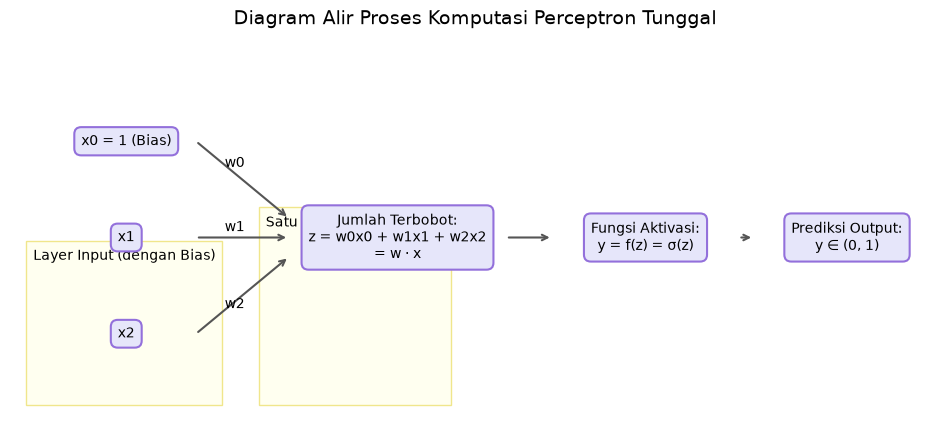

In [11]:
import matplotlib.pyplot as plt

# ==========================================================
# MENYIAPKAN KANVAS GRAFIK
# ==========================================================
fig, ax = plt.subplots(figsize=(12, 5))
ax.set_xlim(0, 12)
ax.set_ylim(0, 6)
ax.axis('off')  # Menyembunyikan garis sumbu X dan Y agar bersih

# Gaya desain untuk kotak teks (Style Box)
box_style = dict(boxstyle="round,pad=0.5", facecolor="#E6E6FA", edgecolor="#9370DB", lw=1.5)
yellow_bg = dict(boxstyle="square,pad=0.5", facecolor="#FFFFF0", edgecolor="#F0E68C", lw=1)

# ==========================================================
# 1. MEMBUAT KOTAK BINGKAI LOKASI (SUBGRAPH AREA)
# ==========================================================
# Bingkai Layer Input
ax.text(0.3, 0.5, "Layer Input (dengan Bias)\n\n\n\n\n\n\n\n", va="bottom", ha="left", bbox=yellow_bg, fontsize=10)
# Bingkai Satu Neuron
ax.text(3.3, 0.5, "Satu Neuron (Perceptron)\n\n\n\n\n\n\n\n\n\n", va="bottom", ha="left", bbox=yellow_bg, fontsize=10)

# ==========================================================
# 2. MENGGAMBAR KOTAK TEKS KOMPONEN UTAMA
# ==========================================================
# Komponen Input
ax.text(1.5, 4.5, "x0 = 1 (Bias)", ha="center", va="center", bbox=box_style, fontsize=10)
ax.text(1.5, 3.0, "x1", ha="center", va="center", bbox=box_style, fontsize=10)
ax.text(1.5, 1.5, "x2", ha="center", va="center", bbox=box_style, fontsize=10)

# Komponen Jumlah Terbobot
z_text = "Jumlah Terbobot:\nz = w0x0 + w1x1 + w2x2\n= w · x"
ax.text(5.0, 3.0, z_text, ha="center", va="center", bbox=box_style, fontsize=10)

# Komponen Fungsi Aktivasi
act_text = "Fungsi Aktivasi:\ny = f(z) = σ(z)"
ax.text(8.2, 3.0, act_text, ha="center", va="center", bbox=box_style, fontsize=10)

# Komponen Output Akhir
out_text = "Prediksi Output:\ny ∈ (0, 1)"
ax.text(10.8, 3.0, out_text, ha="center", va="center", bbox=box_style, fontsize=10)

# ==========================================================
# 3. MENGGAMBAR TANDA PANAH ALIRAN (ARROWS) DAN LABEL BOBOT
# ==========================================================
arrow_style = dict(arrowstyle="->", lw=1.5, color="#555555")

# Panah dari Input ke Jumlah Terbobot beserta teks Label Bobot (w)
ax.annotate("", xy=(3.6, 3.3), xytext=(2.4, 4.5), arrowprops=arrow_style)
ax.text(2.9, 4.1, "w0", fontsize=10, ha="center")

ax.annotate("", xy=(3.6, 3.0), xytext=(2.4, 3.0), arrowprops=arrow_style)
ax.text(2.9, 3.1, "w1", fontsize=10, ha="center")

ax.annotate("", xy=(3.6, 2.7), xytext=(2.4, 1.5), arrowprops=arrow_style)
ax.text(2.9, 1.9, "w2", fontsize=10, ha="center")

# Panah alur internal neuron hingga hasil akhir prediksi
ax.annotate("", xy=(7.0, 3.0), xytext=(6.4, 3.0), arrowprops=arrow_style)
ax.annotate("", xy=(9.6, 3.0), xytext=(9.4, 3.0), arrowprops=arrow_style)

# Menampilkan judul diagram di atas grafik
plt.title("Diagram Alir Proses Komputasi Perceptron Tunggal", fontsize=14, pad=15)

# Perintah wajib di IDLE agar jendela grafik menyembul keluar
plt.show()

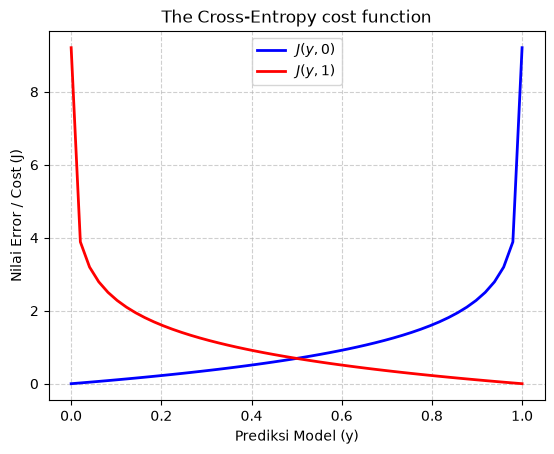

In [18]:
import numpy as np
import matplotlib.pyplot as plt

# ==========================================
# 1. DEFINISI FUNGSI CROSS-ENTROPY LOSS
# ==========================================
def J(y, yhat):
    eps = 1e-8
    return -(yhat * np.log(y + eps) + (1 - yhat) * np.log(1 - y + eps))

def dJdy(y, yhat):
    eps = 1e-8
    return (1 - yhat) / (1 - y + eps) - yhat / (y + eps)

# ==========================================
# 2. MEMBUAT DATA UNTUK GRAFIK
# ==========================================
# Membuat 50 titik angka desimal dari 0.0001 sampai 0.9999
y = np.linspace(0.0001, 0.9999, 50)

# ==========================================
# 3. MENGGAMBAR GRAFIK (MATPLOTLIB)
# ==========================================
plt.figure("Cross-Entropy Cost Function")

# Plot untuk skenario label asli = 0
plt.plot(y, J(y, 0), label='$J(y,0)$', color='blue', linewidth=2)

# Plot untuk skenario label asli = 1
plt.plot(y, J(y, 1), label='$J(y,1)$', color='red', linewidth=2)

# Pengaturan hiasan grafik sesuai modul
plt.legend()
plt.title('The Cross-Entropy cost function')
plt.xlabel('Prediksi Model (y)')
plt.ylabel('Nilai Error / Cost (J)')
plt.grid(True, linestyle='--', alpha=0.6)

# WAJIB di IDLE agar jendela grafik muncul menyembul di layar
plt.show()

In [24]:
#opsi 1

def backward1(x, w, y, yhat):
    z = np.dot(x, w)
    dzdw = x
    return dJdy(y, yhat) * dfdz(z) * dzdw
    
## Opsi 2 menggunakan bentuk eksplisit
def backward2(x, y, yhat):  # w not needed for this form
    return ( y*(1-yhat) - yhat*(1-y) ) * x

def update(w, alpha, step):
    return w - alpha * step

  

In [25]:
  %% Subgraph Layer Input
    subgraph Input_Layer [ Layer Input dengan Bias ]
        x0[ x0 = 1 Bias ]
        x1[ x1 ]
        x2[ x2 ]
    end

    %% Subgraph Perceptron
    subgraph Summation_Activation [  Neuron Tunggal ]
        Sum[ Jumlah Terbobot z ]
        Act[ Fungsi Aktivasi y ]
    end

    %% Output
    Output[ Prediksi Output y ]

    %% Jalur Forward Pass (Garis Hijau)
    x0 -- w0_Forward --> Sum
    x1 -- w1_Forward --> Sum
    x2 -- w2_Forward --> Sum
    Sum -- z --> Act
    Act -- Forward_Pass --> Output

    %% Jalur Backward Pass (Garis Merah Putus-putus)
    Output -. Update_w .-> Act
    Act -. Hitung_Gradient .-> Sum
    Sum -. Error_Backprop .-> x0
    Sum -. Error_Backprop .-> x1
    Sum -. Error_Backprop .-> x2

    %% Penjelasan Warna/Gaya (Legenda)
    style Output fill:#f9f,stroke:#333,stroke-width:2px
    
    %% Mewarnai Jalur Forward (Jalur 0 sampai 4)
    linkStyle 0,1,2,3,4 stroke:#2ecc71,stroke-width:3px;
    
    %% Mewarnai Jalur Backward (Jalur 5 sampai 9)
    linkStyle 5,6,7,8,9 stroke:#e74c3c,stroke-width:2px,stroke-dasharray:5 5;
def train(X, yhat, n_epoch, alpha):
    X_withbias = np.hstack([np.ones((X.shape[0],1)), X])  # fix x_0 = 1
    
    # keep track of performance during training
    costs = np.zeros(shape=(n_epoch,))

    # random nonzero initialization
    w = np.random.normal(0, 0.01, size=(X.shape[1]+1,))  # +1 for the bias

    for epoch in range(n_epoch):
        for i, x in enumerate(X_withbias):
            y = forward(x, w)  # prediction for one sample
            step = backward2(x, y, yhat[i])  # step to take, yhat[i] to just get this sample
            w = update(w, alpha, step)  # update weights
        
        # ### Some niceness to see our progress
        # Calculate total cost after epoch
        predictions = forward(X_withbias, w)  # predictions for entire set
        costs[epoch] = np.mean(J(predictions, yhat))  # mean cost per sample
        
        # report progress
        if ((epoch % 10) == 0) or (epoch == (n_epoch - 1)):
            accuracy = np.mean(predictions.round() == yhat)  # current accuracy on entire set
            print('Training accuracy after epoch {}: {:.4%}'.format(epoch, accuracy))
            
    return w, costs

IndentationError: unexpected indent (1104974262.py, line 1)

Epoch 0 -> Akurasi Pelatihan: 53.40%
Epoch 50 -> Akurasi Pelatihan: 96.70%
Epoch 100 -> Akurasi Pelatihan: 97.30%
Epoch 150 -> Akurasi Pelatihan: 97.80%
Epoch 200 -> Akurasi Pelatihan: 97.80%
Epoch 250 -> Akurasi Pelatihan: 97.90%
Epoch 300 -> Akurasi Pelatihan: 97.90%
Epoch 349 -> Akurasi Pelatihan: 97.90%


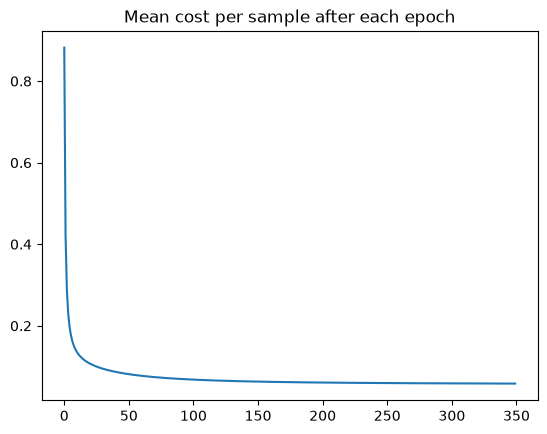

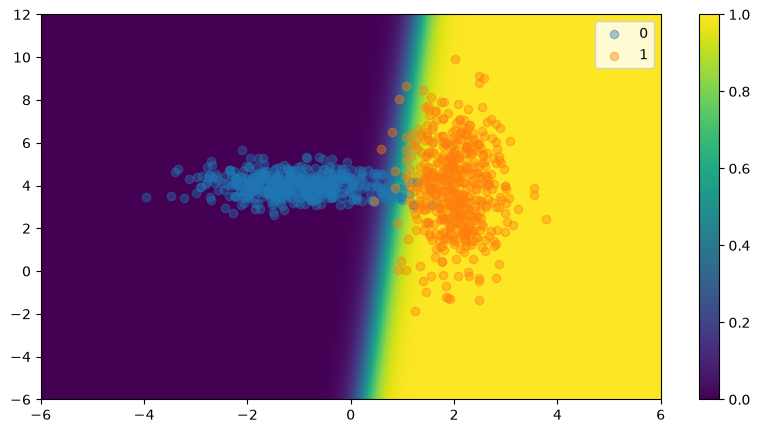

In [27]:
n_epoch = 350
alpha = 0.01

w, costs = train(X, yhat, n_epoch, alpha)    
plt.plot(costs); plt.title('Mean cost per sample after each epoch');

x1 = np.linspace(-6,6,250)
x2 = np.linspace(-6,12,250)
fun_map = np.empty((x1.size, x2.size))
for n,i in enumerate(x1):
    for m,j in enumerate(x2):
        fun_map[m,n] = forward([1,i,j], w)
plt.figure(figsize=(10,5))
plt.imshow(fun_map, extent=[x1.min(),x1.max(),x2.min(),x2.max()], 
           vmin=0, vmax=1, aspect='auto')
plt.colorbar()
plt.scatter(*X[yhat==0].T, label='0', alpha=0.4); plt.scatter(*X[yhat==1].T, label='1', alpha=0.4)
plt.legend();plt.legend();

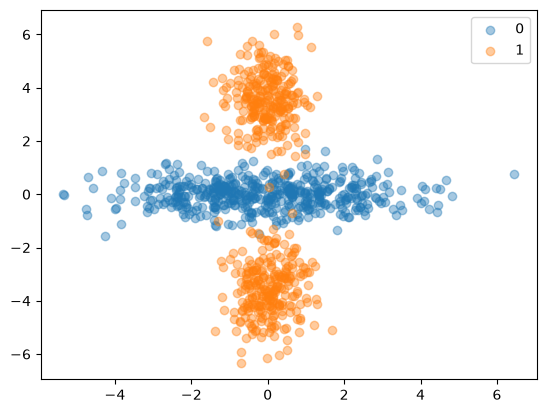

In [28]:
n_samples = 1000
X0 = np.random.normal(loc=[0,0], scale=[2,0.5], size=(int(n_samples/2), 2))
X11 = np.random.normal(loc=[0,3.5], scale=[0.5,1], size=(int(n_samples/4), 2))
X12 = np.random.normal(loc=[0,-3.5], scale=[0.5,1], size=(int(n_samples/4), 2))
X1 = np.vstack([X11, X12])
y0 = np.zeros(shape=(int(n_samples/2), ))
y1 = np.ones(shape=(int(n_samples/2), ))
X = np.vstack([X0, X1])
yhat = np.hstack([y0, y1])

plt.scatter(*X[yhat==0].T, label='0', alpha=0.4); plt.scatter(*X[yhat==1].T, label='1', alpha=0.4)
plt.legend();

Epoch 0 -> Akurasi Pelatihan: 47.50%
Epoch 50 -> Akurasi Pelatihan: 42.50%
Epoch 100 -> Akurasi Pelatihan: 42.50%
Epoch 150 -> Akurasi Pelatihan: 42.50%
Epoch 200 -> Akurasi Pelatihan: 42.50%
Epoch 249 -> Akurasi Pelatihan: 42.50%


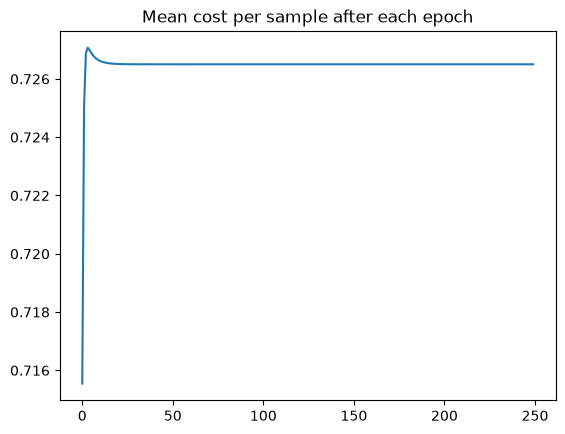

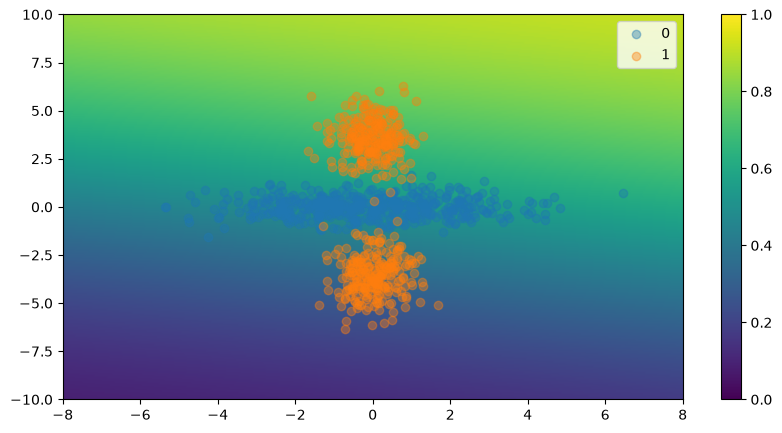

In [29]:
n_epoch = 250
alpha = 0.001

w, costs = train(X, yhat, n_epoch, alpha)    
plt.plot(costs); plt.title('Mean cost per sample after each epoch');
x1 = np.linspace(-8,8,250)
x2 = np.linspace(-10,10,250)
fun_map = np.empty((x1.size, x2.size))
for n,i in enumerate(x1):
    for m,j in enumerate(x2):
        fun_map[m,n] = forward([1,i,j], w)
plt.figure(figsize=(10,5))
plt.imshow(fun_map, extent=[x1.min(),x1.max(),x2.min(),x2.max()], 
           vmin=0, vmax=1, aspect='auto')
plt.colorbar()
plt.scatter(*X[yhat==0].T, label='0', alpha=0.4); plt.scatter(*X[yhat==1].T, label='1', alpha=0.4)
plt.legend();